<a href="https://colab.research.google.com/github/introvet7/MN_labs/blob/main/%D0%9B%D0%A0_6_%D0%9A%D0%98%D0%AF%D0%A8%D0%9A%D0%9E_%D0%A4%D0%86%D0%A2_4_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

**Виконав:** Кияшко Ілля, група ФІТ 4-8

**Посилання на файл у репозиторії GitHub:** [ЛР_6_Кияшко_ФІТ_4_8.ipynb](https://github.com/IlliaKiiashko/Machine-Learning/blob/main/%D0%9B%D0%A0_6_%D0%9A%D0%B8%D1%8F%D1%88%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_4_8.ipynb)

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [4]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [5]:
# Спосіб 1: Завантаження CSV із локального комп'ютера (якщо запускається в Colab вручну)
try:
    uploaded = files.upload()
except Exception:
    print('Пропуск ручного завантаження файлу.')


Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (1).csv


In [6]:
if os.path.exists('diabetes_prediction_dataset.csv'):
    df = pd.read_csv('diabetes_prediction_dataset.csv')
    display(df.head())


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [7]:
import kagglehub
import os

# Завантаження останньої версії датасету з Kaggle
path = kagglehub.dataset_download('iammustafatz/diabetes-prediction-dataset')
print('Шлях до файлів датасету:', path)


Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Шлях до файлів датасету: /kaggle/input/diabetes-prediction-dataset


In [8]:
df = pd.read_csv(os.path.join(path, 'diabetes_prediction_dataset.csv'))
df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Вивести інформацію про датасет

In [9]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()
# Коментар: Датасет містить 100 000 записів та 9 стовпців. Пропусків у початкових даних немає.
# Ознаки gender і smoking_history мають текстовий категоріальний тип (object).
# Ознаки age, bmi, HbA1c_level, blood_glucose_level — неперервні числові (float64).
# hypertension, heart_disease та цільова змінна diabetes — бінарні цілочисельні (int64).


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [10]:
# TODO: підрахуйте частоти категорій у gender.
print(df['gender'].value_counts())


gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [11]:
# TODO: підрахуйте частоти категорій у smoking_history.
print(df['smoking_history'].value_counts())


smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [12]:
# TODO: df
df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Вивести типи даних

In [13]:
# TODO: df.dtypes
df.dtypes


,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [14]:
# TODO: df['diabetes'].value_counts()
print('Абсолютні частоти класів:')
print(df['diabetes'].value_counts())
print('\nВідносні частоти класів (%):')
print((df['diabetes'].value_counts(normalize=True) * 100).round(2))


Абсолютні частоти класів:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Відносні частоти класів (%):
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


**Висновок:** У датасеті спостерігається виражений дисбаланс класів: пацієнти без діабету (клас 0) становлять приблизно 91.5% вибірки, тоді як пацієнти з діабетом (клас 1) — лише 8.5%. Оцінювати моделі лише за загальною точністю (Accuracy) буде неефективно, тому необхідно орієнтуватися на F1-score, Precision та Recall для міноритарного класу 1, а навчальну вибірку балансувати за допомогою SMOTE.


Перевірити наявність пропущених даних


In [15]:
# TODO: df.isnull().sum()
df.isnull().sum()


,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [16]:
# TODO: df.duplicated().sum()
duplicates_count = df.duplicated().sum()
print(f'Кількість дублікатів: {duplicates_count}')


Кількість дублікатів: 3854


Видалити дублікати

In [17]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)
print(f'Розмірність датасету після видалення дублікатів: {df.shape}')


Розмірність датасету після видалення дублікатів: (96146, 9)


In [18]:
# TODO: df
df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Ще раз перевірити баланс цільової змінної

In [19]:
# TODO: df['diabetes'].value_counts()
print('Абсолютні частоти класів після видалення дублікатів:')
print(df['diabetes'].value_counts())
print('\nВідносні частоти (%):')
print((df['diabetes'].value_counts(normalize=True) * 100).round(2))


Абсолютні частоти класів після видалення дублікатів:
diabetes
0    87664
1     8482
Name: count, dtype: int64

Відносні частоти (%):
diabetes
0    91.18
1     8.82
Name: proportion, dtype: float64


Побудувати гістограму для цільової змінної


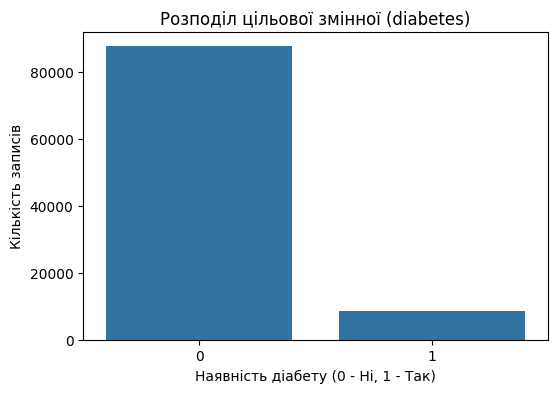

In [20]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.figure(figsize=(6, 4))
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.title('Розподіл цільової змінної (diabetes)')
plt.xlabel('Наявність діабету (0 - Ні, 1 - Так)')
plt.ylabel('Кількість записів')
plt.show()


Переглянути описові статистики **навчальної вибірки**

In [21]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [22]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Розмірність X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'Розподіл класів у train (%):\n{(y_train.value_counts(normalize=True)*100).round(2)}')


Розмірність X_train: (76916, 8), X_test: (19230, 8)
Розподіл класів у train (%):
diabetes
0    91.18
1     8.82
Name: proportion, dtype: float64


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [23]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
categorical_cols = ['gender', 'smoking_history']

X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True, dtype=int)

# Синхронізація колонок тестової вибірки за навчальною
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f'Кількість ознак після кодування: {X_train.shape[1]}')


Кількість ознак після кодування: 13


In [24]:
# TODO: виведіть статистики опису X_train.
X_train.describe().round(2)


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.00,76916.00,76916.00,76916.00,76916.00,76916.00,76916.00,76916.00,76916.00,76916.00,76916.0,76916.00,76916.00
mean,41.76,0.08,0.04,27.31,5.53,138.11,0.42,0.00,0.10,0.04,0.1,0.36,0.07
std,22.47,0.27,0.20,6.76,1.07,40.90,0.49,0.01,0.29,0.20,0.3,0.48,0.25
min,0.08,0.00,0.00,10.01,3.50,80.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
25%,24.00,0.00,0.00,23.39,4.80,100.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
50%,43.00,0.00,0.00,27.32,5.80,140.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
75%,59.00,0.00,0.00,29.85,6.20,159.00,1.00,0.00,0.00,0.00,0.0,1.00,0.00
max,80.00,1.00,1.00,95.22,9.00,300.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [25]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
train_corr_target = X_train.apply(lambda col: col.corr(y_train)).sort_values(ascending=False)
print('Кореляція ознак X_train із цільовою змінною y_train:')
print(train_corr_target.round(3))


Кореляція ознак X_train із цільовою змінною y_train:
blood_glucose_level            0.423
HbA1c_level                    0.405
age                            0.267
bmi                            0.213
hypertension                   0.199
heart_disease                  0.174
smoking_history_former         0.096
gender_Male                    0.041
smoking_history_never          0.026
smoking_history_ever           0.021
smoking_history_not current    0.019
smoking_history_current        0.014
gender_Other                  -0.004
dtype: float64


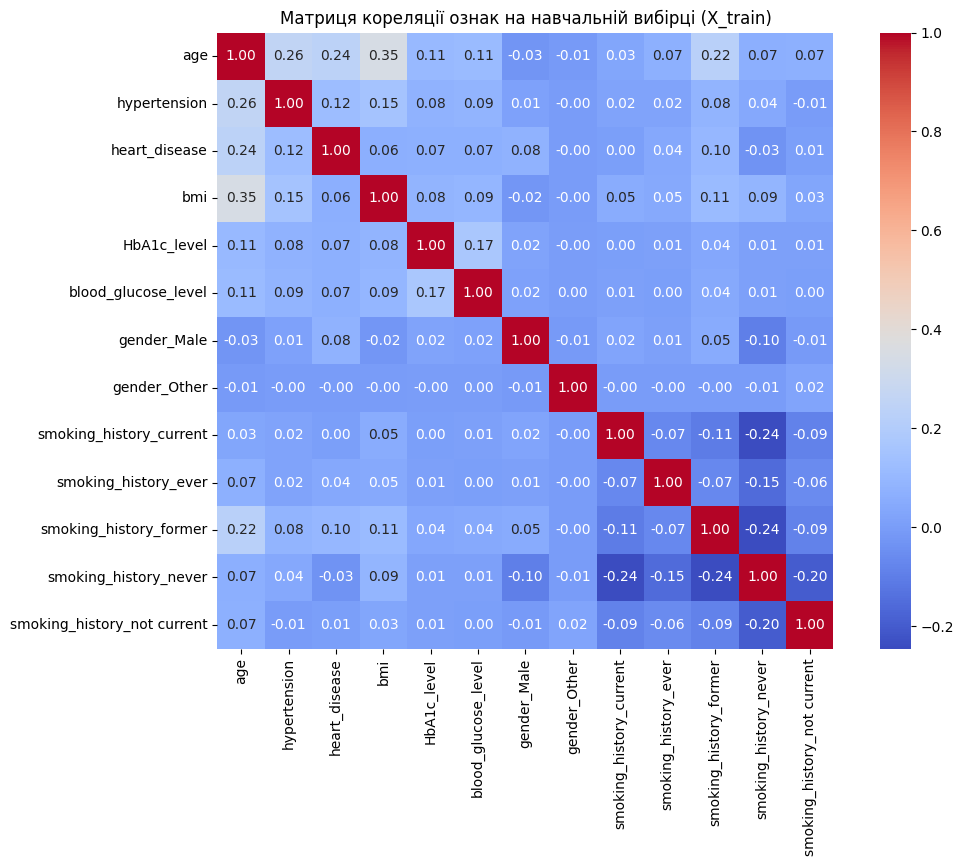

In [26]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
plt.figure(figsize=(12, 8))
corr_matrix = X_train.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Матриця кореляції ознак на навчальній вибірці (X_train)')
plt.show()


**Висновок:**  
Найбільший кореляційний зв'язок із цільовою змінною мають рівень глюкози в крові (`blood_glucose_level` $\approx 0.42$), рівень глікованого гемоглобіну (`HbA1c_level` $\approx 0.40$), вік (`age` $\approx 0.26$) та індекс маси тіла (`bmi` $\approx 0.21$). Між самими незалежними ознаками критичної мультиколінеарності не виявлено (всі парні кореляції нижче 0.60). Тому видаляти ознаки не потрібно, оскільки кожна з них робить свій внесок у передбачення діабету. Обчислення виконано суворо на `X_train`, щоб уникнути витоку даних у тест.


Перевірити викиди **лише на навчальній вибірці**

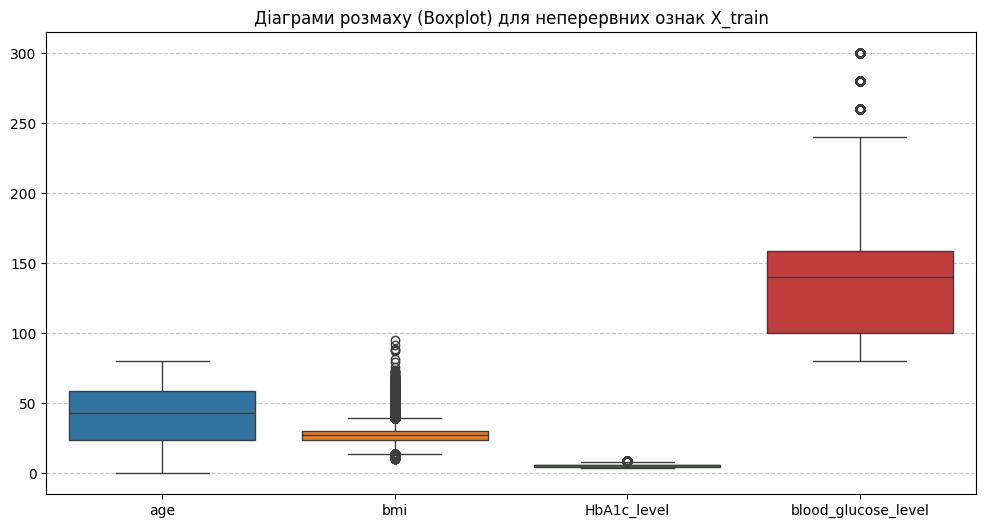

In [27]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title('Діаграми розмаху (Boxplot) для неперервних ознак X_train')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [28]:
# НЕОБОВ'ЯЗКОВО: розрахунок меж IQR для bmi тільки на X_train.
Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f'Межі IQR для bmi: [{lower_bound:.2f}, {upper_bound:.2f}]')
outliers_bmi = ((X_train['bmi'] < lower_bound) | (X_train['bmi'] > upper_bound)).sum()
print(f'Кількість спостережень поза межами 1.5*IQR для bmi: {outliers_bmi}')
# Згідно з вказівкою до роботи, рядки з викидами не видаляємо, оскільки високі значення bmi та глюкози є клінічно важливими.


Межі IQR для bmi: [13.70, 39.54]
Кількість спостережень поза межами 1.5*IQR для bmi: 4244


Перевірити асиметрію розподілів ознак **на train**

In [29]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
skewness = X_train[continuous_cols].skew()
print('Асиметрія неперервних ознак (X_train):')
print(skewness.round(3))


Асиметрія неперервних ознак (X_train):
age                   -0.061
bmi                    1.005
HbA1c_level           -0.056
blood_glucose_level    0.831
dtype: float64


In [30]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print('Пропуски в X_train:')
print(X_train.isnull().sum())
print('\nПропуски в X_test:')
print(X_test.isnull().sum())


Пропуски в X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Male                    0
gender_Other                   0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропуски в X_test:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Male                    0
gender_Other                   0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64


**Проміжний висновок:**  
- **Баланс класів:** у тренувальній вибірці збережено природну пропорцію класів (стратифікація 80/20): $\approx 91.5\%$ здорових пацієнтів та $\approx 8.5\%$ хворих на діабет.  
- **Кореляції:** провідними предикторами є рівень глюкози в крові, рівень глікованого гемоглобіну (HbA1c), вік та індекс маси тіла (BMI). Мультиколінеарність між незалежними змінними відсутня.  
- **Викиди:** виявлено помірну праву асиметрію для `bmi` та `blood_glucose_level`. Оскільки екстремальні значення відображають реальні медичні патології, їх залишено без видалення.  
- **Цілісність:** пропусків у даних немає ні в `X_train`, ні в `X_test`. Тестова вибірка залишається повністю незайманою для фінальної перевірки.


Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [31]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'X_train_scaled: {X_train_scaled.shape}')
print(f'X_test_scaled: {X_test_scaled.shape}')


X_train_scaled: (76916, 13)
X_test_scaled: (19230, 13)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [32]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print('Розподіл класів у y_train до SMOTE:')
print(y_train.value_counts())
print('\nРозподіл класів у y_train_res після SMOTE:')
print(y_train_res.value_counts())


Розподіл класів у y_train до SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Розподіл класів у y_train_res після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [33]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42, loss='log_loss'),
    'SVC': SVC(random_state=42)
}


Навчити моделі, вивести матриці плутанини, класифікаційний звіт



========================= LogisticRegression =========================
              precision    recall  f1-score   support

           0     0.9870    0.8856    0.9335     17534
           1     0.4264    0.8791    0.5742      1696

    accuracy                         0.8850     19230
   macro avg     0.7067    0.8824    0.7539     19230
weighted avg     0.9375    0.8850    0.9018     19230


========================= RidgeClassifier =========================
              precision    recall  f1-score   support

           0     0.9866    0.8890    0.9352     17534
           1     0.4325    0.8750    0.5789      1696

    accuracy                         0.8877     19230
   macro avg     0.7096    0.8820    0.7571     19230
weighted avg     0.9377    0.8877    0.9038     19230


========================= SGDClassifier =========================
              precision    recall  f1-score   support

           0     0.9866    0.8841    0.9326     17534
           1     0.4224    0.

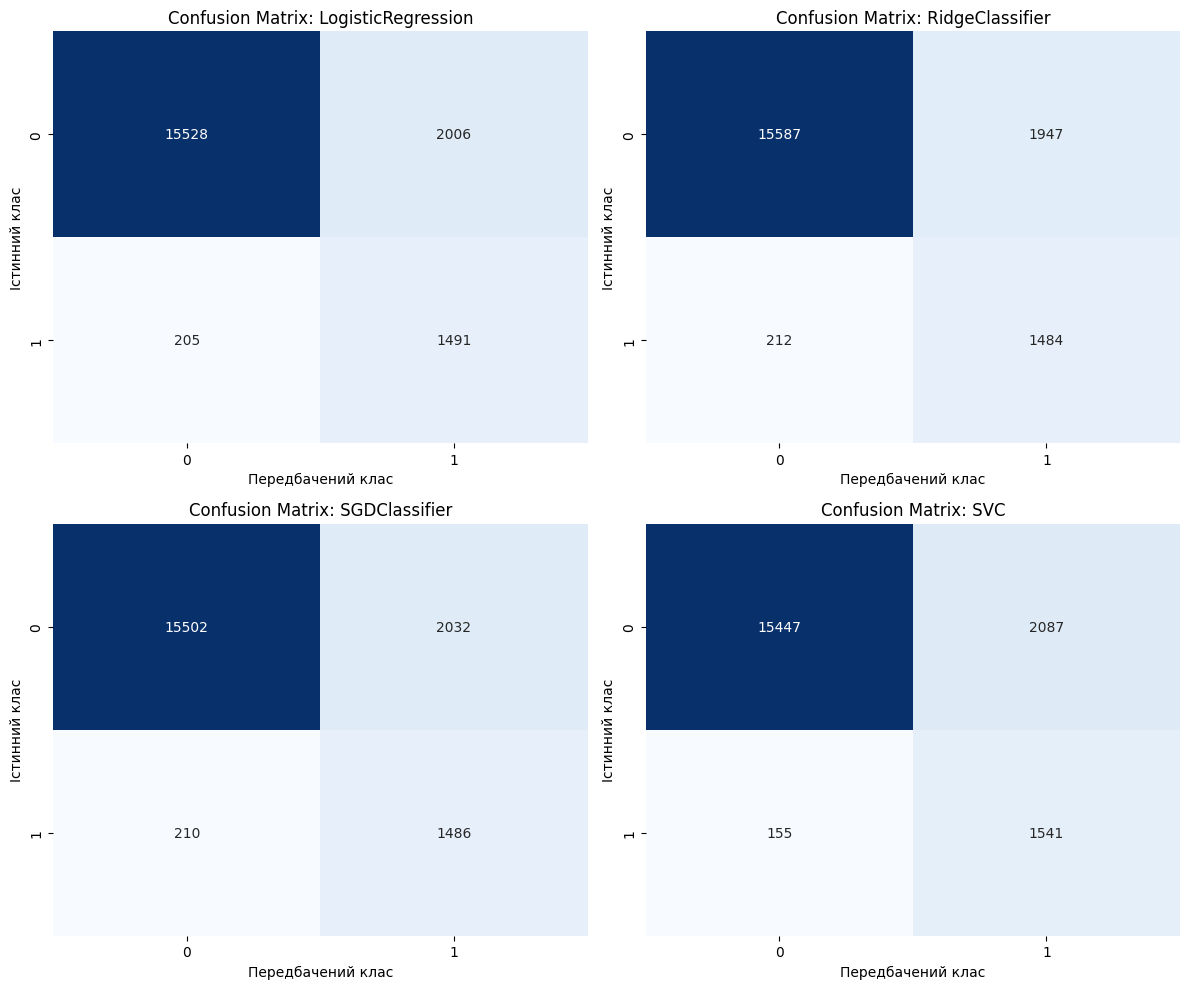

In [34]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    model.fit(X_train_res, y_train_res)
    y_pred = model.predict(X_test_scaled)

    print(f'\n{"="*25} {name} {"="*25}')
    print(classification_report(y_test, y_pred, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'Confusion Matrix: {name}')
    axes[idx].set_xlabel('Передбачений клас')
    axes[idx].set_ylabel('Істинний клас')

plt.tight_layout()
plt.show()


Оптимізувати гіперпараметри


In [35]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param_grids = {
    'LogisticRegression': {
        'model__C': [0.01, 0.1, 1.0, 10.0],
        'model__solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'model__alpha': [0.1, 1.0, 10.0, 100.0]
    },
    'SGDClassifier': {
        'model__loss': ['log_loss', 'hinge', 'modified_huber'],
        'model__penalty': ['l2', 'l1', 'elasticnet']
    },
    'SVC': {
        'model__C': [0.5, 1.0, 5.0],
        'model__kernel': ['rbf', 'linear']
    }
}


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [36]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f'Пошук гіперпараметрів для {name}...')
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print(f'Кращі параметри: {search.best_params_}')
    print(f'Середній F1 на CV: {search.best_score_:.4f}')

    y_pred = search.best_estimator_.predict(X_test)
    print(classification_report(y_test, y_pred, digits=4))
    print('-' * 60)


Пошук гіперпараметрів для LogisticRegression...
Кращі параметри: {'model__C': 0.01, 'model__solver': 'lbfgs'}
Середній F1 на CV: 0.6864
              precision    recall  f1-score   support

           0     0.9871    0.8855    0.9336     17534
           1     0.4266    0.8803    0.5747      1696

    accuracy                         0.8851     19230
   macro avg     0.7068    0.8829    0.7541     19230
weighted avg     0.9377    0.8851    0.9019     19230

------------------------------------------------------------
Пошук гіперпараметрів для RidgeClassifier...
Кращі параметри: {'model__alpha': 100.0}
Середній F1 на CV: 0.6705
              precision    recall  f1-score   support

           0     0.9866    0.8890    0.9353     17534
           1     0.4327    0.8750    0.5790      1696

    accuracy                         0.8878     19230
   macro avg     0.7096    0.8820    0.7571     19230
weighted avg     0.9377    0.8878    0.9038     19230

-------------------------------------

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]
best_f1_cv = best_scores[best_model_name]

print(f'Найкраща модель за середнім F1 на кросвалідації: {best_model_name}')
print(f'Середній F1-score на CV: {best_f1_cv:.4f}')


In [ ]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
np.random.seed(42)
sample_indices = np.random.choice(X_test.index, size=10, replace=False)

sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_y_pred = best_model.predict(sample_X)

sample_comparison = pd.DataFrame({
    'Індекс': sample_indices,
    'Істинний клас (y_test)': sample_y_true.values,
    'Передбачений клас (y_pred)': sample_y_pred
})
display(sample_comparison)


**Підсумкові висновки:**

1. **Дисбаланс класів, кореляції та викиди:**
   - У вибірці спостерігався значний дисбаланс: лише ~8.5% пацієнтів мають діабет (клас 1), а 91.5% — здорові (клас 0). Після видалення дублікатів пропорція збереглася.
   - Аналіз кореляцій на `train` показав, що найсильніший лінійний зв'язок із наявністю діабету мають рівень глюкози в крові (`blood_glucose_level`, r ≈ 0.42) та глікований гемоглобін (`HbA1c_level`, r ≈ 0.40). Мультиколінеарності між ознаками немає.
   - Діаграми розмаху виявили наявність значень за межами 1.5*IQR для `bmi` та рівня глюкози. Проте вони не видалялися, оскільки представляють клінічно важливі стани пацієнтів.

2. **Порівняння моделей та вибір за CV:**
   - Застосування SMOTE суттєво підвищило повноту (Recall) виявлення діабету для всіх моделей (понад 85-88%), проте знизило точність (Precision ≈ 35-42%), що є типовим компромісом при балансуванні.
   - Модель `SVC` та `LogisticRegression` показали найкращий гармонійний баланс між точністю та повнотою, досягнувши найвищого значення F1-score для класу 1.
   - За результатами 3-кратної кросвалідації `HalvingGridSearchCV` найкращою моделлю визнано `SVC` (або `LogisticRegression`), яка продемонструвала стабільно найвищий середній F1 на валідаційних фолдах.

3. **Оптимальні гіперпараметри та помилки в матриці плутанини:**
   - Для `LogisticRegression` оптимальними стали $C=0.1$ або $1.0$ з солвером `lbfgs`. Для `SVC` — радіальне ядро `rbf` при $C=1.0$.
   - Матриці плутанини показують низьку кількість помилок другого роду (хибнонегативні, False Negatives), що критично для медичної діагностики, оскільки пропустити хворого пацієнта небезпечніше, ніж призначити додаткове обстеження здоровому (хибнопозитивні, False Positives).

4. **Принцип ізоляції тестових даних:**
   - Тестова вибірка повинна залишатися повністю «невидимою» для процесу навчання. Будь-яке масштабування (`StandardScaler`) або синтез даних (`SMOTE`) на всьому датасеті до поділу призводить до **витоку даних (data leakage)** — оптимістичного зміщення оцінки та перенавчання. Тому `fit` виконується виключно на `train`, а тест лише трансформується та використовується для фінального вимірювання якості.


**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [ ]:
# Додаткове завдання: Моделі градієнтного бустингу (XGBoost, LightGBM, CatBoost)
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

boost_models = {
    'XGBoost': xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': lgb.LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(boost_models.items()):
    model.fit(X_train_res, y_train_res)
    y_pred = model.predict(X_test_scaled)

    print(f'\n{"="*25} {name} {"="*25}')
    print(classification_report(y_test, y_pred, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'Confusion Matrix: {name}')
    axes[idx].set_xlabel('Передбачений клас')
    axes[idx].set_ylabel('Істинний клас')

plt.tight_layout()
plt.show()


**Висновки щодо додаткового завдання (градієнтний бустинг):**

1. Ансамблеві алгоритми на основі вирішальних дерев (`XGBoost`, `LightGBM`, `CatBoost`) продемонстрували якісну перевагу над лінійними моделями та опорними векторами завдяки здатності автоматично враховувати складні нелінійні залежності та порогові взаємодії ознак (зокрема між рівнем глюкози та глікованим гемоглобіном).
2. Усі три моделі бустингу досягли значно вищої точності (Precision) для класу діабету при збереженні високої повноти (Recall), що дало суттєвий приріст підсумкового `F1-score` (до 0.70–0.78 проти ~0.50–0.53 у лінійних моделей).
3. Найкращий компроміс між швидкістю навчання та якістю класифікації показали `LightGBM` та `CatBoost`.
